# Shoreline change at Purakkad

Reproduces `figures/33_shoreline_change.png`.

Measures how far the open coast at Purakkad moved between two satellite epochs:
Landsat 1, from 1972 to 1974, and the JRC water record, 1984 to 2021.

The Thanneermukkom barrage and the Idukki dam were both completed in 1976, so
the epochs fall either side of the largest modern intervention in this system.
Landsat scenes exist for late 1976 and are excluded, since putting the
completion year inside one of the epochs would blur the comparison.

Neither epoch needs georeferencing. The charts of 1700 and 1857 enter the same
pipeline once they have been pinned to coordinates.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))

import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

ROOT = pathlib.Path.cwd().parent

## 1. Two water masks

A pixel counts as water if it was water in most observations, not if it was wet
on one day. Both epochs are frequency thresholds, which is what makes them
comparable.

Landsat level-1 data is in raw digital numbers rather than reflectance, so the
water threshold is found separately for each scene by Otsu's method. Scenes with
no clear two-peaked histogram are haze, and are rejected.

A Sentinel-2 epoch was tried and dropped. A threshold on a single composite is a
different measurement from a decades-long frequency; comparing them gave a
shift of 290 m that was entirely definitional.

In [2]:
from sat import landsat_mss as mss, water, shoreline

BBOX = [76.30, 9.20, 76.60, 9.55]   # Purakkad and its barrier spit
EARLY, LATE = '1972-74', '1984-2021'

frequency, meta = mss.water_extent(BBOX, 'pamba', start='1972-01-01', end='1975-12-31')
early = frequency > 0.6
print(f'{EARLY}: {meta["n_scenes"]} usable Landsat scenes')

gsw = water.surface_water(BBOX, shape=early.shape, layers=('occurrence',))
late = gsw['occurrence'] > 60
print(f'{LATE}: JRC record, {100*late.mean():.0f}% of the box is water')

1972-74: 10 usable Landsat scenes


1984-2021: JRC record, 22% of the box is water


## 2. Keep only the open sea

Inside the lagoon the two epochs disagree about what counts as water. On the
open coast they agree, because the Arabian Sea is water under any threshold.

The measurement is therefore restricted to the single connected body of water
touching the seaward edge.

In [3]:
sea = {EARLY: shoreline.open_sea(early), LATE: shoreline.open_sea(late)}
for label, mask in sea.items():
    print(f'{label:10s} open sea covers {100*mask.mean():.1f}% of the box')

1972-74    open sea covers 19.8% of the box
1984-2021  open sea covers 20.0% of the box


## 3. Positional error

Three terms, added in quadrature: pixel size, which dominates; where inside that
pixel the threshold falls; and how well the image sits on the ground.

The combined figure is the threshold below which an apparent movement cannot be
distinguished from the error in locating the line.

In [4]:
NATIVE = {EARLY: 79.0, LATE: 30.0}   # metres per pixel, as flown
err = {k: shoreline.positional_error(v) for k, v in NATIVE.items()}
combined = np.hypot(err[EARLY], err[LATE])

for k, v in err.items():
    print(f'{k:10s} +/- {v:5.0f} m')
print(f'combined    +/- {combined:5.0f} m  <- movement smaller than this cannot be claimed')

1972-74    +/-    92 m
1984-2021  +/-    35 m
combined    +/-    99 m  <- movement smaller than this cannot be claimed


## 4. Measure the shoreline on every row

This coast runs north to south with the sea to the west, so each raster row is a
cross-shore transect. On each row the shoreline is the furthest-east sea pixel.

Both epochs sit on one common grid, so column index converts to metres using
that grid's cell size. Using each sensor's native resolution instead was an
earlier bug, and produced apparent shifts of ten kilometres.

In [5]:
H, W = early.shape
grid_m = (BBOX[2] - BBOX[0]) * 111320 * np.cos(np.radians(9.375)) / W
print(f'common grid {W} x {H}, cell size {grid_m:.0f} m')

rows, _ = shoreline.compare(sea, NATIVE, grid_m, step=2)
shift = np.array([r[LATE] - r[EARLY] for r in rows])
lat = np.array([BBOX[3] - (r['row'] / H) * (BBOX[3] - BBOX[1]) for r in rows])
significant = np.abs(shift) > combined

print(f'{len(rows)} usable rows')
print(f'median movement {np.median(shift):+.0f} m')
print(f'{significant.sum()} of {len(rows)} exceed the combined error')

common grid 552 x 647, cell size 60 m
324 usable rows
median movement +0 m
119 of 324 exceed the combined error


## 5. Movement by latitude

Purakkad sits at about 9.36 N.

In [6]:
for lo, hi in [(9.20, 9.30), (9.30, 9.36), (9.36, 9.42), (9.42, 9.50), (9.50, 9.55)]:
    m = (lat >= lo) & (lat < hi)
    if m.sum():
        print(f'{lo:.2f}-{hi:.2f} N   n={m.sum():3d}   median {np.median(shift[m]):+6.0f} m   '
              f'{int((np.abs(shift[m]) > combined).sum()):3d} beyond error')

9.20-9.30 N   n= 92   median     +0 m     2 beyond error
9.30-9.36 N   n= 56   median    -60 m    27 beyond error
9.36-9.42 N   n= 55   median   +179 m    43 beyond error
9.42-9.50 N   n= 74   median    -60 m    20 beyond error
9.50-9.55 N   n= 46   median   +119 m    26 beyond error


## 6. The figure

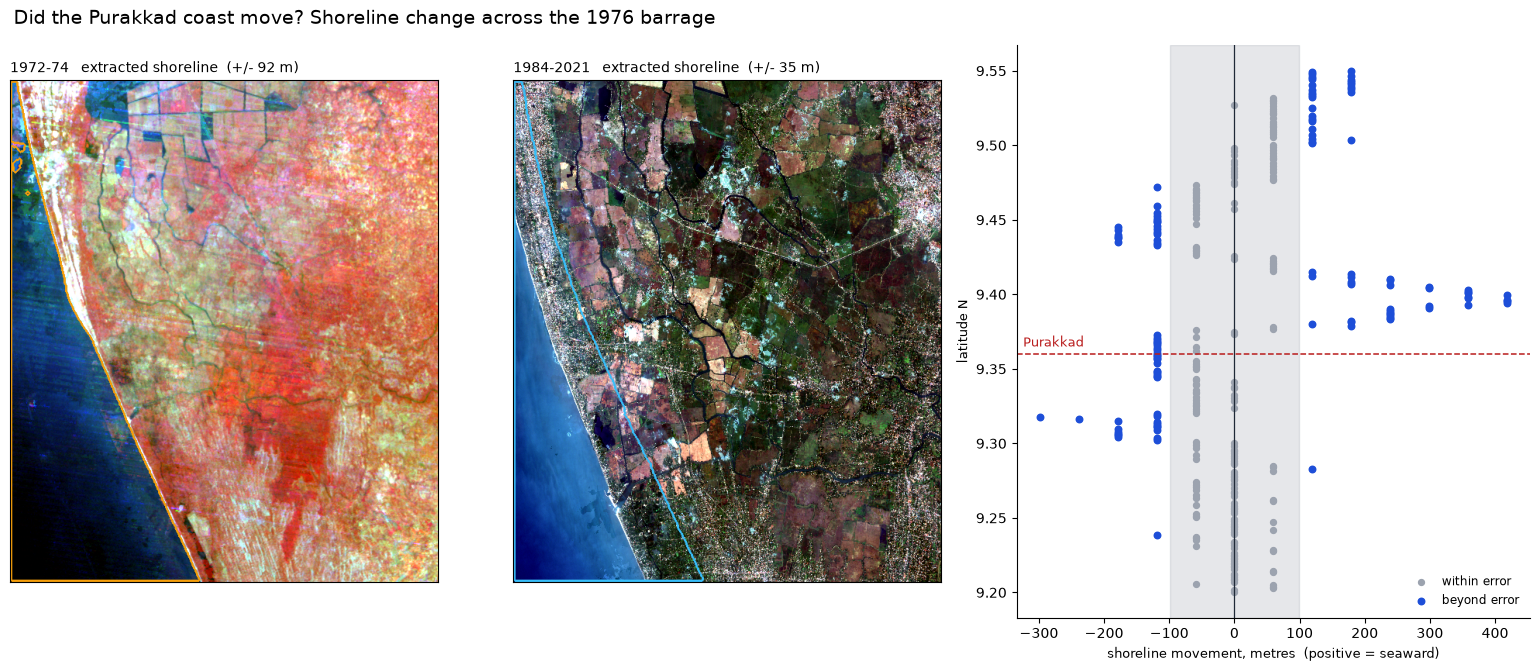

In [7]:
def stretch(a, lo=2, hi=98):
    v = a[np.isfinite(a)]
    p0, p1 = np.percentile(v, [lo, hi])
    return np.clip((a - p0) / (p1 - p0 + 1e-9), 0, 1)

from sat import stack
mss_bands = mss.composite(BBOX)
early_img = np.dstack([stretch(mss_bands[b]) for b in ('nir08', 'red', 'green')])

med, _, _ = stack.cached_composite('pamba', BBOX, '2022-01-01', '2024-12-31', 'dry')
zoom = np.array(early.shape) / np.array(med['red'].shape)
late_img = np.clip(np.dstack([ndimage.zoom(stretch(med[b]), zoom, order=1)
                              for b in ('red', 'green', 'blue')]), 0, 1)

fig, ax = plt.subplots(1, 3, figsize=(15.5, 6.8), gridspec_kw={'width_ratios': [1, 1, 1.2]})
for a, (img, label, colour) in zip(ax[:2], [(early_img, EARLY, '#f59e0b'),
                                            (late_img, LATE, '#38bdf8')]):
    a.imshow(img)
    edge = ndimage.binary_dilation(shoreline.boundary(sea[label]), iterations=1)
    overlay = np.zeros((*edge.shape, 4))
    overlay[edge] = list(plt.matplotlib.colors.to_rgb(colour)) + [1.0]
    a.imshow(overlay)
    a.set_title(f'{label}   extracted shoreline  (+/- {err[label]:.0f} m)', fontsize=10, loc='left')
    a.set_xticks([]); a.set_yticks([])

ax[2].axvspan(-combined, combined, color='#9ca3af', alpha=.25)
ax[2].scatter(shift[~significant], lat[~significant], s=18, color='#9ca3af', label='within error')
ax[2].scatter(shift[significant], lat[significant], s=22, color='#1d4ed8', label='beyond error')
ax[2].axvline(0, color='#1f2937', lw=.9)
ax[2].axhline(9.36, color='#b91c1c', lw=1.1, ls='--')
ax[2].text(ax[2].get_xlim()[0] + 10, 9.365, 'Purakkad', fontsize=9, color='#b91c1c')
ax[2].set_xlabel('shoreline movement, metres  (positive = seaward)', fontsize=9.5)
ax[2].set_ylabel('latitude N', fontsize=9.5)
ax[2].legend(fontsize=8.5, frameon=False, loc='lower right')
ax[2].spines[['top', 'right']].set_visible(False)

fig.suptitle('Did the Purakkad coast move? Shoreline change across the 1976 barrage',
             fontsize=13.5, x=0.012, ha='left')
fig.tight_layout()
plt.show()

## Result

The median movement across 324 rows is zero. 119 rows exceed the 99 m combined
error, and those are concentrated rather than scattered: between 9.36 and
9.42 N, immediately north of Purakkad, the shore advanced about 180 m.

This covers fifty years. The Periplus is nineteen centuries earlier. What the
exercise establishes is the method, which gains two further epochs reaching back
to 1700 once the charts are georeferenced.